
# Earthquake Magnitude and Seismic Activity Analysis Using Statistical Inference

## Objectives
1. Clean and preprocess earthquake data.
2. Calculate descriptive statistics and create statistical graphs.
3. Study probability distributions, random sampling, and the Central Limit Theorem.
4. Perform covariance, correlation, and hypothesis testing.
5. Conduct one-sample, independent two-sample, paired t-tests, chi-square tests, and ANOVA.
6. Build and compare regression and classification models.
7. Evaluate model performance and save the best classification model.


In [3]:

%pip -q install joblib scipy scikit-learn seaborn

import warnings
warnings.filterwarnings("ignore")

import os
import time
import joblib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    ttest_1samp, ttest_ind, ttest_rel,
    f_oneway, chi2_contingency, pearsonr, spearmanr
)

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
np.random.seed(42)

ALPHA = 0.05

print("Libraries imported successfully.")


Libraries imported successfully.


In [4]:

BASE_URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
records = []

for period in pd.date_range("2024-01-01", "2026-01-01", freq="MS")[:-1]:
    start = period.strftime("%Y-%m-%d")
    end = (period + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")

    params = {
        "format": "geojson",
        "starttime": start,
        "endtime": end,
        "minmagnitude": 2.5,
        "orderby": "time-asc",
        "limit": 20000
    }

    try:
        response = requests.get(BASE_URL, params=params, timeout=60)
        response.raise_for_status()

        for feature in response.json().get("features", []):
            p = feature["properties"]
            coords = feature["geometry"]["coordinates"]

            records.append({
                "time": pd.to_datetime(p["time"], unit="ms", utc=True),
                "latitude": coords[1],
                "longitude": coords[0],
                "depth": coords[2],
                "mag": p["mag"],
                "place": p["place"],
                "id": feature["id"]
            })

        print(start, "downloaded")
        time.sleep(0.15)

    except Exception as e:
        print("Download failed for", start, ":", e)

if records:
    df = pd.DataFrame(records)
    df = df.drop_duplicates(subset="id")
    print("Downloaded records:", len(df))
else:
    possible_files = [
        "/content/earthquake_data_large.csv",
        "/content/earthquake_data.csv"
    ]
    existing = next((f for f in possible_files if os.path.exists(f)), None)

    if existing:
        df = pd.read_csv(existing)
        print("Loaded existing file:", existing)
    else:
        raise RuntimeError(
            "Dataset unavailable. Upload earthquake_data_large.csv "
            "using the Colab Files panel, then rerun this cell."
        )

display(df.head())
print("Shape:", df.shape)


2024-01-01 downloaded
2024-02-01 downloaded
2024-03-01 downloaded
2024-04-01 downloaded
2024-05-01 downloaded
2024-06-01 downloaded
2024-07-01 downloaded
2024-08-01 downloaded
2024-09-01 downloaded
2024-10-01 downloaded
2024-11-01 downloaded
2024-12-01 downloaded
2025-01-01 downloaded
2025-02-01 downloaded
2025-03-01 downloaded
2025-04-01 downloaded
2025-05-01 downloaded
2025-06-01 downloaded
2025-07-01 downloaded
2025-08-01 downloaded
2025-09-01 downloaded
2025-10-01 downloaded
2025-11-01 downloaded
2025-12-01 downloaded
Downloaded records: 54391


,time,latitude,longitude,depth,mag,place,id
0,2024-01-01 00:03:15.140000+00:00,18.408667,-66.4270,105.150,3.22,"2 km SSE of Coto Norte, Puerto Rico",pr71435948
1,2024-01-01 00:37:09.096000+00:00,17.662500,145.4596,384.941,4.70,"272 km N of Saipan, Northern Mariana Islands",us6000m0w6
2,2024-01-01 00:54:44.947000+00:00,-57.304500,-25.8967,55.881,4.40,South Sandwich Islands region,us6000m357
3,2024-01-01 00:59:19.656000+00:00,-6.859900,107.1224,178.051,4.10,"4 km SSW of Cianjur, Indonesia",us6000m0wb
4,2024-01-01 01:05:25+00:00,-25.343600,-70.5175,35.000,4.30,"7 km NNW of Taltal, Chile",us6000m0wa


Shape: (54391, 7)


In [5]:

df_clean = df.copy()

df_clean["time"] = pd.to_datetime(
    df_clean["time"], errors="coerce", utc=True
)

for col in ["latitude", "longitude", "depth", "mag"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

df_clean = df_clean.dropna(
    subset=["time", "latitude", "longitude", "depth", "mag"]
)

df_clean = df_clean[
    df_clean["latitude"].between(-90, 90)
    & df_clean["longitude"].between(-180, 180)
    & (df_clean["depth"] >= 0)
    & (df_clean["mag"] > 0)
].copy()

if "id" in df_clean.columns:
    df_clean = df_clean.drop_duplicates(subset="id")

df_clean = df_clean.sort_values("time").reset_index(drop=True)

df_clean["year"] = df_clean["time"].dt.year
df_clean["month"] = df_clean["time"].dt.month
df_clean["hour"] = df_clean["time"].dt.hour
df_clean["day"] = df_clean["time"].dt.day

df_clean["depth_category"] = pd.cut(
    df_clean["depth"],
    bins=[-0.001, 70, 300, np.inf],
    labels=["Shallow", "Intermediate", "Deep"]
)

df_clean["magnitude_category"] = pd.cut(
    df_clean["mag"],
    bins=[-np.inf, 4, 6, np.inf],
    labels=["Low (≤4)", "Moderate (>4–6)", "High (>6)"]
)

# Binary classification target: magnitude >= 4
df_clean["high_magnitude"] = (
    df_clean["mag"] >= 4
).astype(int)

print("Cleaned dataset:", df_clean.shape)
print("Date range:", df_clean["time"].min(), "to", df_clean["time"].max())
print("Missing values:")
display(df_clean.isnull().sum())
display(df_clean.head())


Cleaned dataset: (54245, 14)
Date range: 2024-01-01 00:03:15.140000+00:00 to 2025-12-31 23:57:05.079000+00:00
Missing values:


,0
time,0
latitude,0
longitude,0
depth,0
mag,0
place,0
id,0
year,0
month,0
hour,0


,time,latitude,longitude,depth,mag,place,id,year,month,hour,day,depth_category,magnitude_category,high_magnitude
0,2024-01-01 00:03:15.140000+00:00,18.408667,-66.4270,105.150,3.22,"2 km SSE of Coto Norte, Puerto Rico",pr71435948,2024,1,0,1,Intermediate,Low (≤4),0
1,2024-01-01 00:37:09.096000+00:00,17.662500,145.4596,384.941,4.70,"272 km N of Saipan, Northern Mariana Islands",us6000m0w6,2024,1,0,1,Deep,Moderate (>4–6),1
2,2024-01-01 00:54:44.947000+00:00,-57.304500,-25.8967,55.881,4.40,South Sandwich Islands region,us6000m357,2024,1,0,1,Shallow,Moderate (>4–6),1
3,2024-01-01 00:59:19.656000+00:00,-6.859900,107.1224,178.051,4.10,"4 km SSW of Cianjur, Indonesia",us6000m0wb,2024,1,0,1,Intermediate,Moderate (>4–6),1
4,2024-01-01 01:05:25+00:00,-25.343600,-70.5175,35.000,4.30,"7 km NNW of Taltal, Chile",us6000m0wa,2024,1,1,1,Shallow,Moderate (>4–6),1


In [6]:

numeric_cols = ["mag", "depth", "latitude", "longitude"]

display(df_clean[numeric_cols].describe().T)

summary = pd.DataFrame({
    "Mean": df_clean[numeric_cols].mean(),
    "Median": df_clean[numeric_cols].median(),
    "Mode": df_clean[numeric_cols].mode().iloc[0],
    "Variance": df_clean[numeric_cols].var(),
    "Standard Deviation": df_clean[numeric_cols].std(),
    "Q1": df_clean[numeric_cols].quantile(0.25),
    "Q3": df_clean[numeric_cols].quantile(0.75)
})

display(summary.round(4))


,count,mean,std,min,25%,50%,75%,max
mag,54245.0,3.882817,0.848358,2.5000,3.0000,4.200000,4.5000,8.8000
depth,54245.0,60.705006,109.150281,0.0000,10.0000,16.773000,59.3360,671.0430
latitude,54245.0,22.695932,31.023594,-73.2204,-2.0984,31.042000,51.4151,87.0815
longitude,54245.0,-17.907261,132.353476,-179.9991,-150.9489,-66.979333,127.8870,179.9994


,Mean,Median,Mode,Variance,Standard Deviation,Q1,Q3
mag,3.8828,4.2000,4.400,0.7197,0.8484,3.0000,4.5000
depth,60.7050,16.7730,10.000,11913.7839,109.1503,10.0000,59.3360
latitude,22.6959,31.0420,31.670,962.4634,31.0236,-2.0984,51.4151
longitude,-17.9073,-66.9793,-104.192,17517.4426,132.3535,-150.9489,127.8870


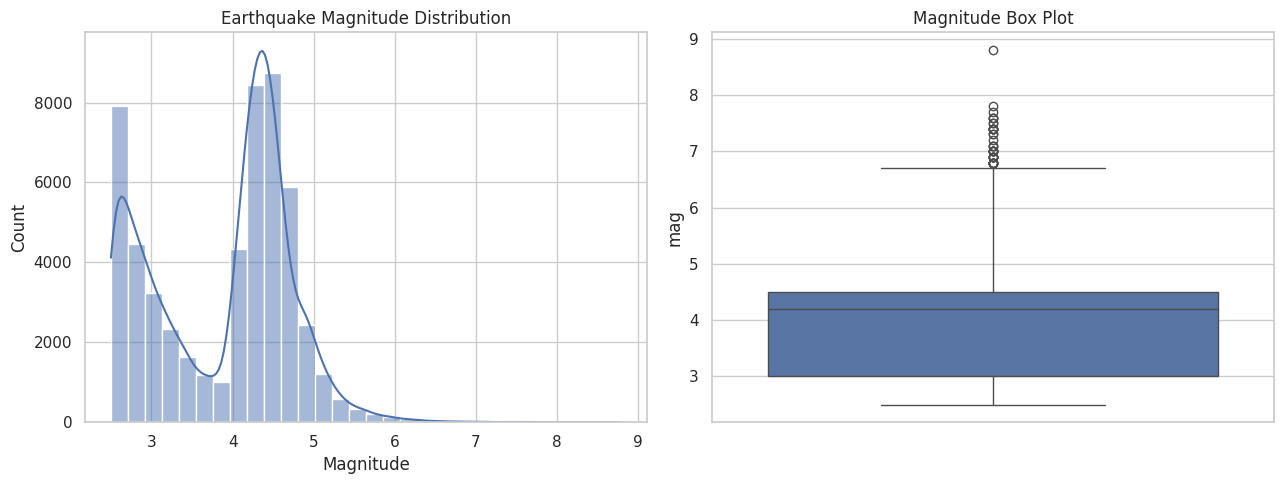

Potential magnitude outliers: 41


,time,place,mag,depth
20,2024-01-01 07:10:09.476000+00:00,"2024 Noto Peninsula, Japan Earthquake",7.5,10.000
1387,2024-01-22 18:09:04.340000+00:00,"128 km WNW of Aykol, China",7.0,13.000
4566,2024-03-03 16:16:53.995000+00:00,Macquarie Island region,6.8,23.187
5749,2024-03-23 20:22:04.348000+00:00,"36 km ENE of Ambunti, Papua New Guinea",6.9,41.464
6394,2024-04-02 23:58:12.173000+00:00,"15 km S of Hualien City, Taiwan",7.4,40.000
6696,2024-04-05 11:03:16.357000+00:00,"Maug Islands region, Northern Mariana Islands",6.8,222.000
12533,2024-06-28 05:36:36.902000+00:00,"10 km WSW of Atiquipa, Peru",7.2,24.000
13349,2024-07-11 02:13:18.585000+00:00,"106 km WSW of Sangay, Philippines",7.1,639.503
13827,2024-07-19 01:50:48.571000+00:00,"41 km ESE of San Pedro de Atacama, Chile",7.4,127.291
14898,2024-08-02 22:23:02.111000+00:00,"20 km E of Barcelona, Philippines",6.8,32.000


In [7]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df_clean["mag"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Earthquake Magnitude Distribution")
axes[0].set_xlabel("Magnitude")

sns.boxplot(y=df_clean["mag"], ax=axes[1])
axes[1].set_title("Magnitude Box Plot")

plt.tight_layout()
plt.show()

q1 = df_clean["mag"].quantile(0.25)
q3 = df_clean["mag"].quantile(0.75)
iqr = q3 - q1

outliers = df_clean[
    (df_clean["mag"] < q1 - 1.5 * iqr)
    | (df_clean["mag"] > q3 + 1.5 * iqr)
]

print("Potential magnitude outliers:", len(outliers))
display(outliers[["time", "place", "mag", "depth"]].head(10))


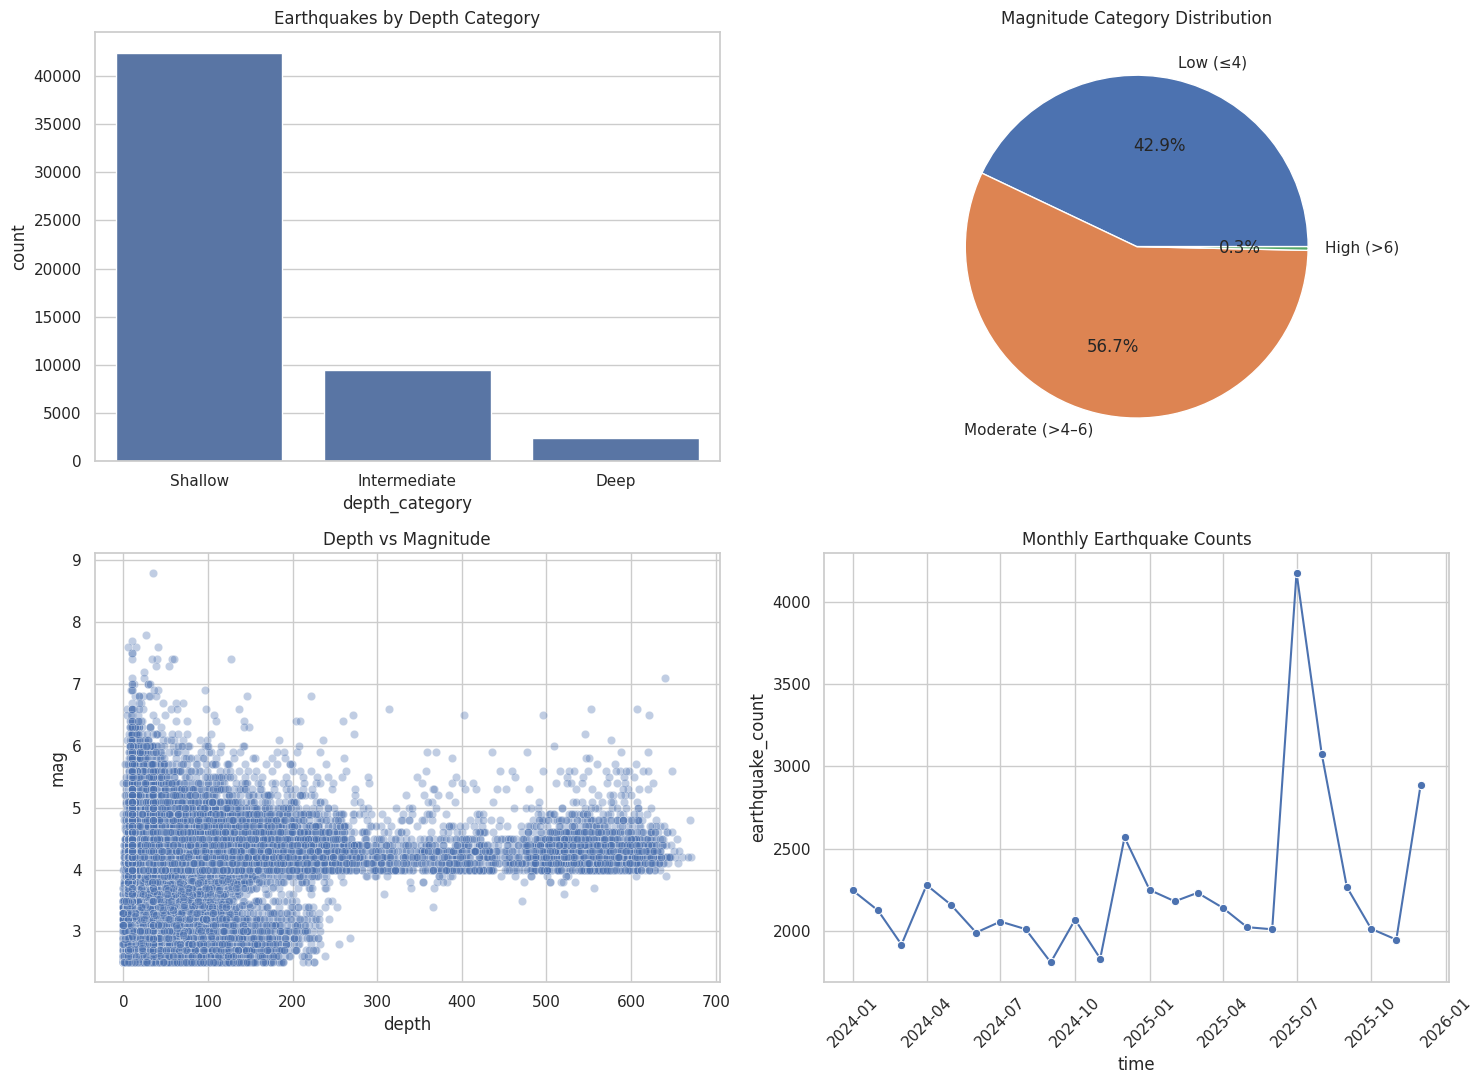

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.countplot(
    data=df_clean,
    x="depth_category",
    order=["Shallow", "Intermediate", "Deep"],
    ax=axes[0, 0]
)
axes[0, 0].set_title("Earthquakes by Depth Category")

df_clean["magnitude_category"].value_counts().sort_index().plot.pie(
    autopct="%1.1f%%", ax=axes[0, 1]
)
axes[0, 1].set_title("Magnitude Category Distribution")
axes[0, 1].set_ylabel("")

sns.scatterplot(
    data=df_clean, x="depth", y="mag", alpha=0.35, ax=axes[1, 0]
)
axes[1, 0].set_title("Depth vs Magnitude")

monthly = (
    df_clean.set_index("time")
    .resample("MS")
    .agg(earthquake_count=("mag", "count"))
    .reset_index()
)

sns.lineplot(
    data=monthly, x="time", y="earthquake_count",
    marker="o", ax=axes[1, 1]
)
axes[1, 1].set_title("Monthly Earthquake Counts")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


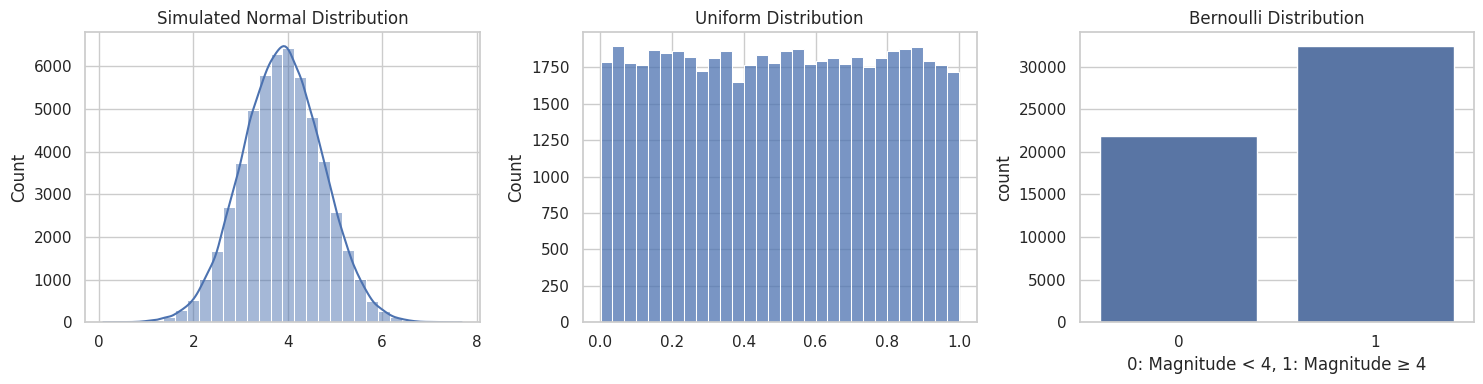

Observed proportion with magnitude >= 4: 0.5987


In [9]:

n = len(df_clean)
magnitudes = df_clean["mag"].to_numpy()

normal_sample = np.random.normal(
    magnitudes.mean(), magnitudes.std(), n
)
uniform_sample = np.random.uniform(0, 1, n)

p = (magnitudes >= 4).mean()
bernoulli_sample = np.random.binomial(1, p, n)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(normal_sample, bins=30, kde=True, ax=axes[0])
axes[0].set_title("Simulated Normal Distribution")

sns.histplot(uniform_sample, bins=30, ax=axes[1])
axes[1].set_title("Uniform Distribution")

sns.countplot(x=bernoulli_sample, ax=axes[2])
axes[2].set_title("Bernoulli Distribution")
axes[2].set_xlabel("0: Magnitude < 4, 1: Magnitude ≥ 4")

plt.tight_layout()
plt.show()

print("Observed proportion with magnitude >= 4:", round(p, 4))


In [10]:

population = df_clean["mag"].reset_index(drop=True)
sample_size = min(100, len(population))

simple_sample = population.sample(sample_size, random_state=42)
with_replacement = population.sample(
    sample_size, replace=True, random_state=42
)
without_replacement = population.sample(
    sample_size, replace=False, random_state=21
)

step = max(1, len(population) // sample_size)
systematic_sample = population.iloc[::step].head(sample_size)

sampling_summary = pd.DataFrame({
    "Sample": [
        "Population", "Simple random", "With replacement",
        "Without replacement", "Systematic"
    ],
    "Mean Magnitude": [
        population.mean(), simple_sample.mean(),
        with_replacement.mean(), without_replacement.mean(),
        systematic_sample.mean()
    ]
})

display(sampling_summary.round(4))


,Sample,Mean Magnitude
0,Population,3.8828
1,Simple random,4.0049
2,With replacement,3.8373
3,Without replacement,3.9357
4,Systematic,4.0218


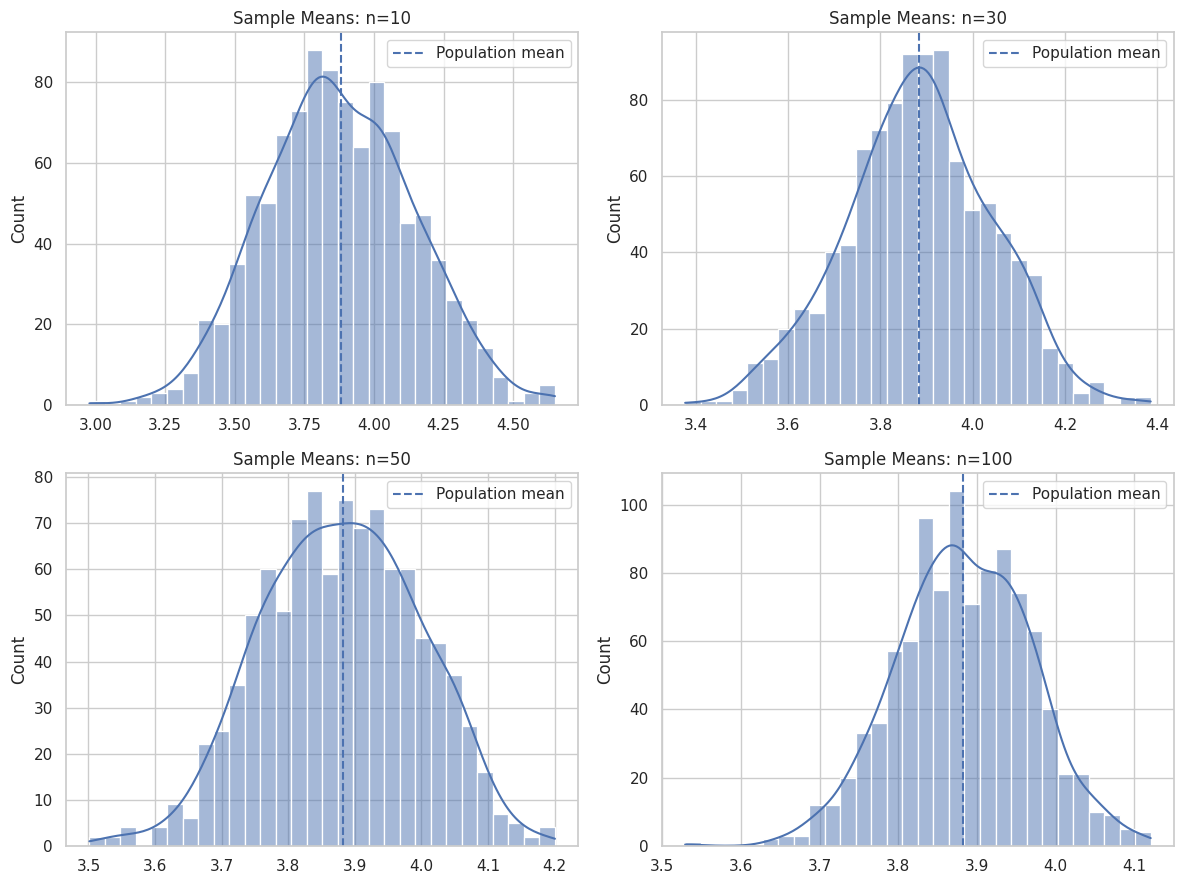

,Sample Size,Mean of Sample Means,Observed SE,Theoretical SE
0,10,3.8751,0.2640,0.2683
1,30,3.8838,0.1574,0.1549
2,50,3.8797,0.1180,0.1200
3,100,3.8832,0.0845,0.0848


In [11]:

np.random.seed(42)

sample_sizes = [10, 30, 50, 100]
repetitions = 1000

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
clt_results = []

for ax, size in zip(axes.flatten(), sample_sizes):
    means = [
        np.mean(np.random.choice(population, size=size, replace=True))
        for _ in range(repetitions)
    ]

    sns.histplot(means, bins=30, kde=True, ax=ax)
    ax.axvline(population.mean(), linestyle="--", label="Population mean")
    ax.set_title(f"Sample Means: n={size}")
    ax.legend()

    clt_results.append({
        "Sample Size": size,
        "Mean of Sample Means": np.mean(means),
        "Observed SE": np.std(means, ddof=1),
        "Theoretical SE": population.std(ddof=1) / np.sqrt(size)
    })

plt.tight_layout()
plt.show()

display(pd.DataFrame(clt_results).round(4))


In [12]:

sample = population.sample(
    n=min(100, len(population)), random_state=42
)

estimates = pd.DataFrame({
    "Parameter": ["Mean magnitude", "Variance of magnitude"],
    "Population Value": [
        population.mean(), population.var(ddof=1)
    ],
    "Sample Estimate": [
        sample.mean(), sample.var(ddof=1)
    ]
})

display(estimates.round(4))


,Parameter,Population Value,Sample Estimate
0,Mean magnitude,3.8828,4.0049
1,Variance of magnitude,0.7197,0.6184


Covariance:
15.582123806673094

Pearson
Coefficient: 0.1683
P-value: 0.0
Direction: positive
Strength: weak
Decision: Reject H0
Significant: True

Spearman
Coefficient: 0.1675
P-value: 0.0
Direction: positive
Strength: weak
Decision: Reject H0
Significant: True

Alpha = 0.05


,Magnitude,Depth
Magnitude,0.719711,15.582124
Depth,15.582124,11913.783945


,Magnitude,Depth
Magnitude,1.000000,0.168276
Depth,0.168276,1.000000


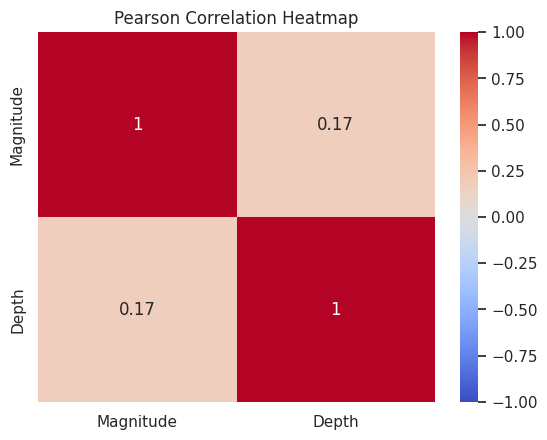

In [13]:

data = df_clean[["mag", "depth"]].dropna().copy()
data.columns = ["Magnitude", "Depth"]

# Covariance
print("Covariance:")
print(data["Magnitude"].cov(data["Depth"]))

# Pearson correlation and test
pearson_r, pearson_p = pearsonr(data["Magnitude"], data["Depth"])

# Spearman rank correlation and test
spearman_r, spearman_p = spearmanr(data["Magnitude"], data["Depth"])

def interpret_correlation(r):
    direction = "positive" if r > 0 else "negative" if r < 0 else "none"
    strength = (
        "negligible" if abs(r) < 0.10 else
        "weak" if abs(r) < 0.30 else
        "moderate" if abs(r) < 0.50 else "strong"
    )
    return direction, strength

for name, coefficient, pvalue in [
    ("Pearson", pearson_r, pearson_p),
    ("Spearman", spearman_r, spearman_p)
]:
    direction, strength = interpret_correlation(coefficient)
    print(f"\n{name}")
    print("Coefficient:", round(coefficient, 4))
    print("P-value:", pvalue)
    print("Direction:", direction)
    print("Strength:", strength)
    print("Decision:", "Reject H0" if pvalue < ALPHA else "Fail to reject H0")
    print("Significant:", pvalue < ALPHA)

print("\nAlpha =", ALPHA)

# Covariance and correlation matrices
display(data.cov())
display(data.corr(method="pearson"))

sns.heatmap(data.corr(), annot=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Pearson Correlation Heatmap")
plt.show()


In [14]:

sample_magnitudes = df_clean["mag"].dropna()

test_stat, p_value = ttest_1samp(sample_magnitudes, popmean=4)

print("One-Sample T-Test")
print("Sample mean:", sample_magnitudes.mean())
print("t-statistic:", test_stat)
print("p-value:", p_value)
print("Decision:", "Reject H0" if p_value < ALPHA else "Fail to reject H0")


One-Sample T-Test
Sample mean: 3.8828170550577985
t-statistic: -32.171043604587986
p-value: 5.930881907199987e-225
Decision: Reject H0


In [15]:

shallow = df_clean.loc[
    df_clean["depth_category"] == "Shallow", "mag"
].dropna()

deep = df_clean.loc[
    df_clean["depth_category"] == "Deep", "mag"
].dropna()

if len(shallow) >= 2 and len(deep) >= 2:
    t_stat, p_value = ttest_ind(shallow, deep, equal_var=False)

    print("Welch Two-Sample T-Test")
    print("Shallow mean:", shallow.mean(), "| n =", len(shallow))
    print("Deep mean:", deep.mean(), "| n =", len(deep))
    print("t-statistic:", t_stat)
    print("p-value:", p_value)
    print("Decision:", "Reject H0" if p_value < ALPHA else "Fail to reject H0")
else:
    print("Not enough records in both groups.")


Welch Two-Sample T-Test
Shallow mean: 3.8166916940290667 | n = 42434
Deep mean: 4.357027257240204 | n = 2348
t-statistic: -66.17613430761291
p-value: 0.0
Decision: Reject H0


In [16]:

monthly_counts = (
    df_clean.set_index("time")["mag"]
    .resample("MS").count()
)

monthly_table = monthly_counts.rename("count").reset_index()
monthly_table["year"] = monthly_table["time"].dt.year
monthly_table["month"] = monthly_table["time"].dt.month

wide = monthly_table.pivot(
    index="month", columns="year", values="count"
)

if 2024 in wide.columns and 2025 in wide.columns:
    paired = wide[[2024, 2025]].dropna()

    if len(paired) >= 2:
        t_stat, p_value = ttest_rel(paired[2025], paired[2024])

        print("Paired T-Test: Monthly counts, 2025 vs 2024")
        print("Paired months:", len(paired))
        print("2024 average monthly count:", paired[2024].mean())
        print("2025 average monthly count:", paired[2025].mean())
        print("t-statistic:", t_stat)
        print("p-value:", p_value)
        print("Decision:", "Reject H0" if p_value < ALPHA else "Fail to reject H0")
    else:
        print("Not enough matching months for a paired test.")
else:
    print("Both 2024 and 2025 are needed for this test.")


Paired T-Test: Monthly counts, 2025 vs 2024
Paired months: 12
2024 average monthly count: 2087.5833333333335
2025 average monthly count: 2432.8333333333335
t-statistic: 1.8345817956631068
p-value: 0.09373315540999261
Decision: Fail to reject H0


In [17]:

contingency = pd.crosstab(
    df_clean["depth_category"],
    df_clean["magnitude_category"]
)

display(contingency)

chi2_stat, p_value, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2_stat)
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("Decision:", "Reject H0" if p_value < ALPHA else "Fail to reject H0")

expected_df = pd.DataFrame(
    expected,
    index=contingency.index,
    columns=contingency.columns
)
print("Expected frequencies:")
display(expected_df.round(2))


magnitude_category,Low (≤4),Moderate (>4–6),High (>6)
depth_category,,,
Shallow,20135,22143,156
Intermediate,2916,6523,24
Deep,245,2094,9


Chi-square statistic: 1944.8969800498994
Degrees of freedom: 4
p-value: 0.0
Decision: Reject H0
Expected frequencies:


magnitude_category,Low (≤4),Moderate (>4–6),High (>6)
depth_category,,,
Shallow,18223.66,24062.49,147.85
Intermediate,4063.97,5366.06,32.97
Deep,1008.37,1331.45,8.18


Group sizes: [42434, 9463, 2348]
Group means: [np.float64(3.8167), np.float64(4.0617), np.float64(4.357)]
ANOVA F-statistic: 724.8699009730923
p-value: 2.120685480871e-311
Decision: Reject H0


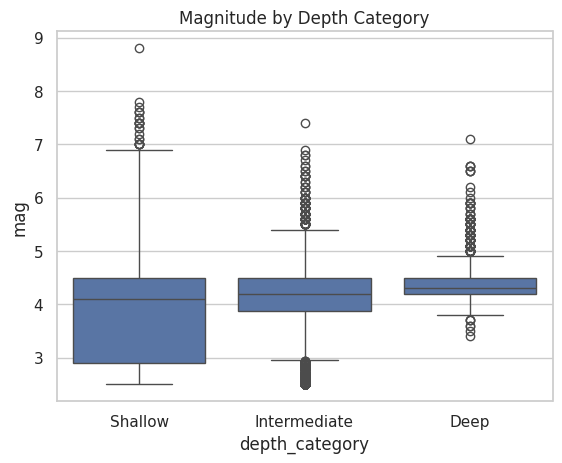

In [18]:

groups = [
    df_clean.loc[df_clean["depth_category"] == category, "mag"].dropna()
    for category in ["Shallow", "Intermediate", "Deep"]
]

print("Group sizes:", [len(g) for g in groups])
print("Group means:", [round(g.mean(), 4) if len(g) else None for g in groups])

if all(len(g) >= 2 for g in groups):
    f_stat, p_value = f_oneway(*groups)

    print("ANOVA F-statistic:", f_stat)
    print("p-value:", p_value)
    print("Decision:", "Reject H0" if p_value < ALPHA else "Fail to reject H0")

    sns.boxplot(
        data=df_clean,
        x="depth_category",
        y="mag",
        order=["Shallow", "Intermediate", "Deep"]
    )
    plt.title("Magnitude by Depth Category")
    plt.show()
else:
    print("Not enough observations for ANOVA.")


In [19]:

features = ["depth", "latitude", "longitude", "month", "hour"]
target = "high_magnitude"

model_data = df_clean[features + [target]].dropna().copy()

X = model_data[features]
y = model_data[target].astype(int)

print("Class distribution:")
display(y.value_counts().rename(index={0: "Magnitude < 4", 1: "Magnitude >= 4"}))

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Class distribution:


,count
high_magnitude,
Magnitude >= 4,32478
Magnitude < 4,21767


Training records: 43396
Testing records: 10849


In [20]:

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced"))
])

logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)

print("LOGISTIC REGRESSION")
print(classification_report(y_test, logistic_pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, logistic_pred))


LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.89      0.92      0.90      4353
           1       0.94      0.93      0.93      6496

    accuracy                           0.92     10849
   macro avg       0.92      0.92      0.92     10849
weighted avg       0.92      0.92      0.92     10849

Accuracy: 0.9219282883215043


In [21]:

tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print("DECISION TREE")
print(classification_report(y_test, tree_pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, tree_pred))


DECISION TREE
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      4353
           1       0.99      0.97      0.98      6496

    accuracy                           0.97     10849
   macro avg       0.97      0.97      0.97     10849
weighted avg       0.97      0.97      0.97     10849

Accuracy: 0.972071158632132


In [22]:

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("RANDOM FOREST")
print(classification_report(y_test, rf_pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, rf_pred))


RANDOM FOREST
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      4353
           1       0.99      0.97      0.98      6496

    accuracy                           0.97     10849
   macro avg       0.97      0.97      0.97     10849
weighted avg       0.97      0.97      0.97     10849

Accuracy: 0.9722555074200387


In [23]:

knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

print("K-NEAREST NEIGHBORS")
print(classification_report(y_test, knn_pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, knn_pred))


K-NEAREST NEIGHBORS
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      4353
           1       0.98      0.95      0.96      6496

    accuracy                           0.96     10849
   macro avg       0.95      0.96      0.96     10849
weighted avg       0.96      0.96      0.96     10849

Accuracy: 0.9568623836298277


In [24]:

svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

print("SUPPORT VECTOR MACHINE")
print(classification_report(y_test, svm_pred, zero_division=0))
print("Accuracy:", accuracy_score(y_test, svm_pred))


SUPPORT VECTOR MACHINE
              precision    recall  f1-score   support

           0       0.89      0.98      0.93      4353
           1       0.99      0.92      0.95      6496

    accuracy                           0.94     10849
   macro avg       0.94      0.95      0.94     10849
weighted avg       0.95      0.94      0.94     10849

Accuracy: 0.9434049221126372


In [ ]:
classification_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model,
    "K-Nearest Neighbors": knn_model,
    "Support Vector Machine": svm_model
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, candidate in classification_models.items():
    scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "CV F1 Std": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV F1", ascending=False
)

display(cv_df.round(4))

best_name = cv_df.iloc[0]["Model"]
best_model = classification_models[best_name]

best_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print("Held-out test F1:", round(f1_score(y_test, best_pred, zero_division=0), 4))
print("Held-out test accuracy:", round(accuracy_score(y_test, best_pred), 4))
print(classification_report(y_test, best_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, best_pred)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()


In [ ]:

model_filename = "best_earthquake_classifier.joblib"

joblib.dump(best_model, model_filename)

print("Saved best model:", model_filename)
print("Selected algorithm:", best_name)

# Test loading the saved model
loaded_model = joblib.load(model_filename)

sample_predictions = loaded_model.predict(X_test.iloc[:5])
print("Sample predictions:", sample_predictions)
print("Actual labels:", y_test.iloc[:5].to_list())


In [ ]:

from google.colab import files
files.download("best_earthquake_classifier.joblib")


In [ ]:

regression_features = ["depth", "latitude", "longitude", "month", "hour"]

regression_data = df_clean[regression_features + ["mag"]].dropna()

X_reg = regression_data[regression_features]
y_reg = regression_data["mag"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

regression_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

regression_model.fit(Xr_train, yr_train)
reg_predictions = regression_model.predict(Xr_test)

mae = mean_absolute_error(yr_test, reg_predictions)
mse = mean_squared_error(yr_test, reg_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(yr_test, reg_predictions)

print("MULTIPLE LINEAR REGRESSION")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R²:", round(r2, 4))

plt.figure(figsize=(7, 5))
sns.scatterplot(x=yr_test, y=reg_predictions, alpha=0.5)

low = min(yr_test.min(), reg_predictions.min())
high = max(yr_test.max(), reg_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual Magnitude")
plt.ylabel("Predicted Magnitude")
plt.title("Actual vs Predicted Earthquake Magnitudes")
plt.tight_layout()
plt.show()


In [ ]:

df_clean.to_csv("earthquake_data_cleaned.csv", index=False)
comparison.to_csv("classification_model_comparison.csv", index=False)
cv_df.to_csv("cross_validation_results.csv", index=False)

regression_predictions = pd.DataFrame({
    "Actual Magnitude": yr_test.to_numpy(),
    "Predicted Magnitude": reg_predictions
})
regression_predictions.to_csv("regression_predictions.csv", index=False)

regression_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2"],
    "Value": [mae, mse, rmse, r2]
})
regression_metrics.to_csv("regression_metrics.csv", index=False)

print("All project outputs saved successfully.")


In [ ]:

from google.colab import files

for filename in [
    "earthquake_data_cleaned.csv",
    "classification_model_comparison.csv",
    "cross_validation_results.csv",
    "regression_predictions.csv",
    "regression_metrics.csv"
]:
    files.download(filename)


In [ ]:
app_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(
    page_title="Earthquake Magnitude Classifier",
    page_icon="🌋",
    layout="centered"
)

st.title("🌋 Earthquake Magnitude Classifier")
st.write("""
This interactive app uses a trained **Random Forest Classifier** to predict whether
an earthquake will have a **High Magnitude (>= 4.0)** or **Low Magnitude (< 4.0)**
based on seismic properties.
""")

try:
    model = joblib.load("best_earthquake_classifier.joblib")
    st.success("✅ Model successfully loaded!")
except Exception as e:
    st.error(f"❌ Could not load model: {e}. Please ensure 'best_earthquake_classifier.joblib' is present in the directory.")
    st.stop()

st.header("Predict Earthquake Severity")

col1, col2 = st.columns(2)

with col1:
    depth = st.number_input("Depth (km)", min_value=0.0, max_value=800.0, value=15.0, step=0.1, help="Depth of the earthquake focus in kilometers.")
    latitude = st.number_input("Latitude", min_value=-90.0, max_value=90.0, value=35.0, step=0.01, help="Latitude coordinate.")
    longitude = st.number_input("Longitude", min_value=-180.0, max_value=180.0, value=-120.0, step=0.01, help="Longitude coordinate.")

with col2:
    month = st.slider("Month of the Year", min_value=1, max_value=12, value=6, help="Month when the event occurred.")
    hour = st.slider("Hour of the Day", min_value=0, max_value=23, value=12, help="Hour of the day (0-23 UTC) when the event occurred.")

input_data = pd.DataFrame([{
    'depth': depth,
    'latitude': latitude,
    'longitude': longitude,
    'month': month,
    'hour': hour
}])

st.markdown("--- ")
if st.button("⚡ Predict Magnitude Classification", use_container_width=True):
    prediction = model.predict(input_data)[0]
    probabilities = model.predict_proba(input_data)[0]

    st.subheader("Prediction Results")

    if prediction == 1:
        st.error(f"🚨 **High Magnitude (>= 4.0)** expected!")
    else:
        st.info(f"🟢 **Low Magnitude (< 4.0)** expected.")

    st.write(f"**Probability distribution:**")
    st.write(f"- Low Magnitude (< 4.0): **{probabilities[0] * 100:.2f}%**")
    st.write(f"- High Magnitude (>= 4.0): **{probabilities[1] * 100:.2f}%**")
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("Streamlit frontend app.py has been successfully generated without string interpolation conflicts.")